# 🧴 Dermatology Agent (Dr. Zavian) — RAG Evaluation Notebook
**MedNexus AI Platform · Local, open-weight pipeline (Ollama)**
Generator **MedGemma (7B)** → Judge **Qwen 2.5-14B** · 100 queries (50 diagnosis + 50 medication)

> This notebook uses the **same evaluation method as the ENT agent notebook** (two different local models, guardrails on the generator, 5 LLM-judge metrics, embedding-based retrieval metrics), configured with the **dermatology** index, dataset and retrieval settings.

---
## 📌 What this notebook does
It evaluates a Retrieval-Augmented-Generation (RAG) agent for dermatology in two layers:

| Layer | Question answered | How it is measured | Needs an LLM? |
|---|---|---|---|
| **Retrieval** | Did the system find the right text? | Cosine similarity (BGE-large) between ground truth and each retrieved chunk → Recall, Precision, MRR, NDCG, P@k, R@k | No |
| **Generation** | Is the final answer good? | Qwen 2.5-14B as judge, 5 RAGAS-style metrics → Faithfulness, Correctness, Context Precision, Answer Relevance, Context Recall | Yes |

## 🔄 Pipeline (per query)
```
question ─► Pinecone (MedEmbed, top-10) ─► BGE reranker ─► top-5 chunks ─► context (≤7,000 chars, ≤1,200/chunk)
                                                                              │
                      ground truth ──┬───────────────────────────────────────┤
                                     ▼                                         ▼
                 Retrieval metrics (embedding-based)          MedGemma answer (+ guardrail retries)
                                                                              │
                                                                              ▼
                                                           Qwen 2.5-14B judge → 5 generation metrics
```

## ⚙️ Fixed configuration
| Setting | Value |
|---|---|
| Generator LLM | `medgemma` (Ollama), temperature 0 |
| Judge LLM | `qwen2.5:14b` (Ollama), temperature 0, JSON mode |
| Pinecone index / namespaces | `dermatologist` / `diagnosis_knowledge`, `medication_knowledge` |
| Retrieval embeddings | `abhinand/MedEmbed-base-v0.1` |
| Similarity model (metrics only) | `BAAI/bge-large-en-v1.5`, relevance threshold **0.50** |
| Reranker | `BAAI/bge-reranker-v2-m3` (top-10 → top-5) |
| Context budget | 7,000 chars total, 1,200 per chunk |
| Generation / judge max tokens | 600 / 1,000 (context window 16,384) |
| Queries | first 50 per namespace → **100** |

## 🧠 Why two different models?
* **No self-evaluation bias** – the judge (Qwen) is a different model family from the generator (MedGemma).
* **Role fit** – MedGemma is medically tuned (generation); Qwen 2.5-14B is a larger general reasoning model (judging).
* **Local & reproducible** – both run through Ollama on the Kaggle GPU: no API key, no per-token cost, no rate limits, no patient text leaves the machine.

## 🛡️ Generator guardrails (same as ENT, applied before scoring)
The first answer is checked for four failure modes and regenerated (max 2 retries) if one is found:
| Failure mode | Detection | Retry instruction |
|---|---|---|
| Repetition loop | ≥3 identical lines, last 200 chars repeated ≥3×, or type-token ratio < 0.15 | "Do not repeat. Write 3-5 bullet points only." |
| Truncation | does not end with terminal punctuation | "Finish every sentence with a period." |
| Vague dose | "appropriate dose", "individualized", "dose per weight/age" | "Quote specific doses/concentrations verbatim." |
| Missing dose | treatment/drug question but no number + unit in the answer | same as above |

*Dermatology adaptation:* the "dose present" check also accepts **`%`** (topical strengths such as 0.05 %), which the ENT version did not need.
Retry lines are printed in the log (`⚠ Retry n/2 (reason)`); a query can still fail a check after the retries – read the log to see how often.

## ▶️ How to run (Kaggle)
1. **Accelerator:** GPU (T4 ×2 recommended) · **Internet:** ON.
2. **Secrets:** `PINECONE_API_KEY` (a key with access to index `dermatologist`).
3. **Add Data:** the dermatology evaluation dataset; if your CSV path differs, edit `DATASET_PATH` in Section 2 of Part B.
4. Run **Part A** (install) → **Restart kernel** → run **Part B** (evaluation).
5. All results are printed at the end of Part B and saved to files.

## 📂 Files produced (working directory)
| File | Contents |
|---|---|
| `derm_results_<run>_*.csv` | one row per query: retrieval metrics + 5 judge scores |
| `derm_judgments_<run>_*.csv` | one row per query: full generated answer + 5 judge scores |
| `derm_metrics_<run>_*.json` | aggregated summary (overall / diagnosis / medication) |
| `derm_evaluation_plots_<run>.png` | 9-panel figure |

## 🗺️ Where to find each item
| Item | Location |
|---|---|
| Configuration (all parameters) | Part B · **Step 2 – Configuration** |
| Prompts (generation + 5 judges) | Part B · **Step 5 – Prompts** |
| Guardrails | Part B · **Step 6 – `LLMEvaluator.generate_with_retry`** |
| Retrieval metric formulas | Part B · **Step 7 – `retrieval_metrics`** |
| LLM-judge metrics | Part B · **Step 6 – `LLMEvaluator.evaluate_all`** |
| Overall + per-namespace results | Part B · **Step 11 – Aggregate** and **Step 13 – Final report** |
| Runtime | output line `Loop completed in … min` |

## ⚠️ Notes for reviewers
* Retrieval metrics are **embedding-only**; MRR / P@k / R@k use a fixed threshold (0.50) and tend to saturate near 1.0. The *continuous* Recall/Precision are the discriminative retrieval measures.
* "Success rate" = queries with ≥1 retrieved chunk and no exception (system reliability, **not** clinical correctness).
* Generator and judge use `temperature = 0` (loop retries use 0.3), so reruns are deterministic up to GPU/numerical noise.
* Scores printed by this notebook come from **this** run; they replace any earlier Llama 3-only or Llama-4-Scout numbers.

---
# 📖 Metric Guide (for reviewers)
## What Every Metric Means

This section explains, in plain English, what each number printed by the notebook actually measures — so a reader can interpret the results without prior RAG-evaluation background.

### A. Retrieval metrics (embedding-based)

These measure **how good the retrieved passages are**, by comparing each passage against the reference (ground-truth) answer using cosine similarity of an independent sentence encoder (`BAAI/bge-large-en-v1.5`). They do **not** involve the LLM. A passage is called *relevant* when its similarity to the ground truth is ≥ `SIMILARITY_THRESHOLD` (0.50).

| Metric | What it means | How it is computed | How to read it |
|---|---|---|---|
| **Context Recall (continuous)** | How well the *best* retrieved passage matches the ground-truth answer. | `max(similarity(ground_truth, doc))` over the top-5 passages. | 1.0 = the best passage is essentially the gold answer. 0.0 = nothing retrieved resembles it. Higher is better. |
| **Context Precision (continuous)** | How well the *whole* top-5 set matches the ground-truth answer on average. | `mean(similarity(ground_truth, doc))` over the top-5 passages. | 1.0 = every retrieved passage is relevant. Low values mean irrelevant passages dilute the context. Higher is better. |
| **MRR** (Mean Reciprocal Rank) | Rank of the *first* relevant passage. | `1 / rank_of_first_relevant_passage`, averaged over queries. | 1.0 = a relevant passage is always rank 1. 0.5 = first relevant at rank 2. Only cares about the *first* hit. |
| **NDCG** (Normalized Discounted Cumulative Gain) | Graded ranking quality — rewards relevant passages higher up, not just "is there one". | DCG / IDCG using per-passage similarity as gain. | 1.0 = perfect ordering by relevance. 0.99 = near-perfect. Less saturated than MRR. |
| **Precision@k** | Fraction of the top-k passages that are relevant. | `(# relevant in top-k) / k`. | 1.0 = every one of the top-k passages is relevant. 0.2 = only 1 of 5 is relevant. Higher is better. |
| **Recall@k** | Whether *at least one* relevant passage appears in the top-k. | `1.0` if any top-k passage is relevant, else `0.0`. | 1.0 = at least one relevant passage in the top-k. 0.0 = none. Binary, coarser than Precision@k. |

### B. Generation metrics (LLM-as-judge)

These measure **how good the generated answer is**, using Qwen 2.5-14B as evaluator (a different model family from the MedGemma generator). Each metric is scored 0–1 from a structured JSON reply. If the judge returns invalid JSON, the score silently defaults to 0, so a few unusually low scores can indicate a parsing failure rather than a bad answer.

| Metric | What it means | What the judge is asked | How to read it |
|---|---|---|---|
| **Faithfulness** | Is the answer *grounded* in the retrieved context, or does it hallucinate? | For each claim in the answer, is it supported by the context? Score = supported claims / total claims. **Special rule:** if the answer says "the provided context does not contain information", score = 1.0 (correct abstention counts as faithful). | 1.0 = every claim is traceable to the context. 0.5 = half the claims are unsupported. Higher is better; low values indicate hallucination. |
| **Answer Correctness** | Does the answer agree with the reference answer (ground truth)? | Semantic + factual overlap between the generated answer and the ground truth. | 1.0 = perfectly correct. 0.0 = completely wrong. Higher is better; this is the strictest quality signal. |
| **Context Precision (LLM)** | Is the retrieved context *focused* on what the question asks, or does it contain noise? | Proportion of the context that is directly relevant to the question. | 1.0 = all context is relevant. 0.0 = nothing relevant. Higher is better; low values point to noisy retrieval. |
| **Answer Relevance** | Does the answer actually *answer* the question that was asked? | Does the answer directly address the question, regardless of whether it is correct? | 1.0 = perfectly on-topic. 0.0 = off-topic (e.g., answering a different question). Higher is better; low values mean the model dodged the question. |
| **Context Recall (LLM)** | Does the retrieved context *cover* all the facts in the ground truth? | Proportion of ground-truth information that appears in the context. | 1.0 = every gold fact is present in the context. 0.0 = none. Higher is better; low values indicate missing information. |

### C. Why MRR may be exactly 1.0 (and why that is not suspicious)
MRR records only the **rank of the first relevant chunk**. After BGE reranking a chunk above the 0.50 threshold is usually ranked first, so MRR (and Precision@1 / Recall@k) sits at or near 1.0 and stops being informative. The more discriminative retrieval numbers are **continuous Recall** and **continuous Precision**, which show whether the *whole* top-5 set is on topic. MRR = 1.0 means "the top hit is relevant", not "retrieval is perfect".

### D. Technical request-completion (success) rate
A **system-reliability** measure: queries where retrieval returned at least one chunk and no exception was raised (`best_similarity > 0`). It does **not** check medical correctness – that is covered by Answer Correctness and Faithfulness.

### E. Things to watch in the output log
- `Reranker enabled False` → reranking failed to load; the run is **not** using the cross-encoder and MRR should not be trusted.
- `⚠ Retry n/2 (loop | trunc | vague | missing)` → a guardrail fired for that query.
- `✗ ERROR:` → the query failed and was stored with all scores = 0 (this lowers the averages).

In [ ]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()

secret_value_2 = user_secrets.get_secret("PINECONE_API_KEY")
secret_value_3 = user_secrets.get_secret("PINECONE_API_KEY_PHRAMACY")


---
# 🅰️ PART A — Environment Setup *(run once, then restart the kernel)*
Installs Ollama, NumPy 2.x, Pinecone v5, LangChain-core, sentence-transformers, etc. Nothing in this part computes a metric.
> ⚠️ After the last cell of Part A finishes, use **Run → Restart & Clear Cell Outputs**, then continue with Part B.

### A.1 · Install system + Python dependencies

In [ ]:
"""
CELL 1 — INSTALL ONLY
Run once, then RESTART KERNEL, then run Cell 2.
"""
import subprocess, sys, time, importlib

print("=" * 70)
print("CELL 1: Install dependencies")
print("=" * 70)

# ── Clean Pinecone ──
print("  Cleaning Pinecone packages...")
for pkg in ["pinecone-client", "pinecone", "langchain", "langchain-community"]:
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", pkg],
                   check=False, capture_output=True)
for path in [
    "/usr/local/lib/python3.13/dist-packages/pinecone",
    "/usr/local/lib/python3.13/dist-packages/pinecone_client",
    "/usr/local/lib/python3.13/dist-packages/langchain",
]:
    subprocess.run(["rm", "-rf", path], check=False)
for mod in list(sys.modules.keys()):
    if "pinecone" in mod or mod == "langchain":
        del sys.modules[mod]
importlib.invalidate_caches()
print("  Cleanup done")

# ── System deps ──
subprocess.run(["apt-get", "install", "-y", "zstd"], check=False)

# ── Install Ollama binary ──
try:
    subprocess.run(["ollama", "--version"], check=True, capture_output=True, timeout=5)
    print("  Ollama binary present")
except Exception:
    print("  Installing Ollama binary...")
    subprocess.run("curl -fsSL https://ollama.com/install.sh | sh", shell=True, check=True)

# ── Install Python packages ──
print("  Installing Python packages...")

# Step A: numpy 2.x first (fix "dtype size changed")
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
    "--force-reinstall", "numpy>=2.0,<3.0", "pandas>=2.0"], check=True)

# Step B: ollama + pinecone
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
    "ollama>=0.4.0",
    "pinecone>=5.4.0,<6.0.0"], check=True)

# Step C: langchain CORE only (no `langchain` meta package)
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
    "langchain-core>=0.3.0,<0.4.0",
    "langchain-huggingface>=0.1.0",
    "langchain-pinecone>=0.2.0",
    "sentence-transformers>=2.7.0",
    "python-dotenv>=1.0.0",
    "tqdm>=4.66.0",
    "matplotlib>=3.7.0",
    "seaborn>=0.13.0"], check=True)

# ── Verify ──
print("  Verifying...")
import numpy
print(f"    numpy {numpy.__version__}")
assert numpy.__version__.startswith("2."), "numpy must be >=2.0"
from pinecone import Pinecone
import pinecone as pc_pkg
print(f"    pinecone {getattr(pc_pkg, '__version__', '?')}")
import ollama
print(f"    ollama OK")
import langchain_core
print(f"    langchain-core {langchain_core.__version__}")

print("\n" + "=" * 70)
print("CELL 1 COMPLETE")
print("=" * 70)
print("\n  ⚠️ RESTART KERNEL NOW, then run Cell 2.")
print("  Kaggle: Run → Restart & Clear Cell Outputs")
print("  Colab:  Runtime → Restart runtime")
print("=" * 70)

### A.2 · Remove deprecated Pinecone inference plugin
*(avoids import conflicts with `pinecone>=5.4`)*

In [ ]:
# ── Remove deprecated pinecone-plugin-inference ──
print("  Removing deprecated pinecone-plugin-inference...")
subprocess.run(
    [sys.executable, "-m", "pip", "uninstall", "-y",
     "pinecone-plugin-inference", "pinecone-client"],
    check=False, capture_output=True,
)

# Also remove any leftover plugin directory
for path in [
    "/usr/local/lib/python3.13/dist-packages/pinecone_plugin_inference",
    "/usr/local/lib/python3.13/dist-packages/pinecone-plugin-inference",
]:
    subprocess.run(["rm", "-rf", path], check=False)

# Clear cached modules
for mod in list(sys.modules.keys()):
    if "pinecone" in mod:
        del sys.modules[mod]
importlib.invalidate_caches()
print("  Plugin cleanup done")

### A.3 · Sanity check of imports
Expected last line: `✅ All imports OK — proceed to Part B`.

In [1]:
# ── Verify (quick check, ~5 sec) ──
print("  Verifying...")
import numpy
print(f"    numpy {numpy.__version__}")
assert numpy.__version__.startswith("2."), "numpy must be >=2.0"

from pinecone import Pinecone
import pinecone as pc_pkg
print(f"    pinecone {getattr(pc_pkg, '__version__', '?')}")

import ollama
print(f"    ollama OK")

import langchain_core
print(f"    langchain-core {langchain_core.__version__}")

print("\n  ✅ All imports OK — proceed to Part B")

  Verifying...
    numpy 2.4.6
    pinecone 7.3.0
    ollama OK
    langchain-core 0.3.79

  ✅ All imports OK — proceed to Part B


---
# 🅱️ PART B — Full Evaluation (single cell)
The cell below is organised in **13 numbered sections**. Search for the banner `# ====` to jump between them.
It pulls two models on first use: `medgemma` (generator) and `qwen2.5:14b` (judge).

| # | Section | What happens |
|---|---|---|
| 0 | Imports + display helpers | pretty-printing utilities (no logic) |
| 1 | Ollama + models | start server, pull `medgemma` and `qwen2.5:14b` |
| 2 | Configuration | **all tunable parameters** (threshold 0.50, k 10→5, context 7,000 chars, dataset path) |
| 3 | Credentials | Pinecone key from `.env` or Kaggle Secrets |
| 4 | Embeddings + reranker | MedEmbed (retrieval), BGE-large (metric similarity), BGE-reranker-v2-m3 |
| 5 | Prompts | generation prompt + 5 judge prompts |
| 6 | Classes | `OllamaChat`, `LLMEvaluator` (generation, guardrails, judging) |
| 7 | Retrieval + metrics | `retrieve`, `combine_context`, `retrieval_metrics` |
| 8 | Pin models in GPU | keeps both models loaded for 30 min |
| 9 | Dataset | selects 50 diagnosis + 50 medication questions |
| 10 | Evaluation loop | per query: retrieve → generate → score |
| 11 | Aggregate + save | CSV/JSON files |
| 12 | Figure | 9-panel PNG |
| 13 | Final report | summary printed at the bottom of the output |

/usr/local/lib/python3.12/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
2026-10-25 16:07:11.703127: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792944431.968422     287 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792944432.039986     287 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792944432.684537     287 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792944432.684594     287 computation_pl


  STEP 1/7 · OLLAMA SERVER + MODELS
  Status                         Starting server...
    Status                       Server up
  Ensuring medgemma           ... OK
  Ensuring qwen2.5:14b        ... OK

  STEP 2/7 · CONFIGURATION
    Generator model              medgemma
    Evaluator model              qwen2.5:14b
    Index                        dermatologist
    Context budget (chars)       7000 total / 1200 per chunk
    K (retrieve → rerank → final) 10 → 5
    Similarity threshold         0.5
    Generation max tokens        600
    Evaluation max tokens        1000
    Diagnosis queries            30
    Medication queries           30
    Stream answers               True

  STEP 3/7 · API CREDENTIALS
    Source                       PINECONE_API_KEY
    Status                       Loaded OK

  STEP 4/7 · EMBEDDING MODELS + RERANKER
  Loading MedEmbed (embedding model)...

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/201 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

...

Overall:  98%|██████████████████████████████▍| 59/60 [24:41<00:23, 23.73s/query, [60/60] medication]

 0.200  (4.5s)

──────────────────────────────────────────────────────────────────────────────
  Query score summary
──────────────────────────────────────────────────────────────────────────────
    Faithfulness      [████████████████░░░░] 0.800
    Answer Correctness[████████████░░░░░░░░] 0.600
    Context Precision [██████░░░░░░░░░░░░░░] 0.300
    Answer Relevance  [█████████████████░░░] 0.850
    Context Recall    [████░░░░░░░░░░░░░░░░] 0.200

╔════════════════════════════════════════════════════════════════════════════╗
║ QUERY 60/60  ·  MEDICATION_KNOWLEDGE          ║
╚════════════════════════════════════════════════════════════════════════════╝
  Q: What is azathioprine used for?

  ── RETRIEVAL ──
  5 docs retrieved in 0.7s
  Reranker: ON

  Rank     Rerank  Preview
  ------ --------  ----------------------------------------------------------
  1        0.9459  101 Sarah H. Wakelin  + Classification & mode of action T...
  2        0.8882  102 Azathioprine  + Indications & derm

Overall: 100%|███████████████████████████████| 60/60 [25:03<00:00, 25.06s/query, [60/60] medication]

 0.800  (5.0s)

──────────────────────────────────────────────────────────────────────────────
  Query score summary
──────────────────────────────────────────────────────────────────────────────
    Faithfulness      [████████████████████] 1.000
    Answer Correctness[████████████████░░░░] 0.800
    Context Precision [█████████████████░░░] 0.850
    Answer Relevance  [███████████████████░] 0.950
    Context Recall    [████████████████░░░░] 0.800

  Loop completed in 25.1 min (25.1s per query)

  AGGREGATING RESULTS

  GENERATING FIGURE (9 panels)



/tmp/ipykernel_287/2960937233.py:788: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([d_s, m_s], labels=["Diagnosis","Medication"], patch_artist=True)


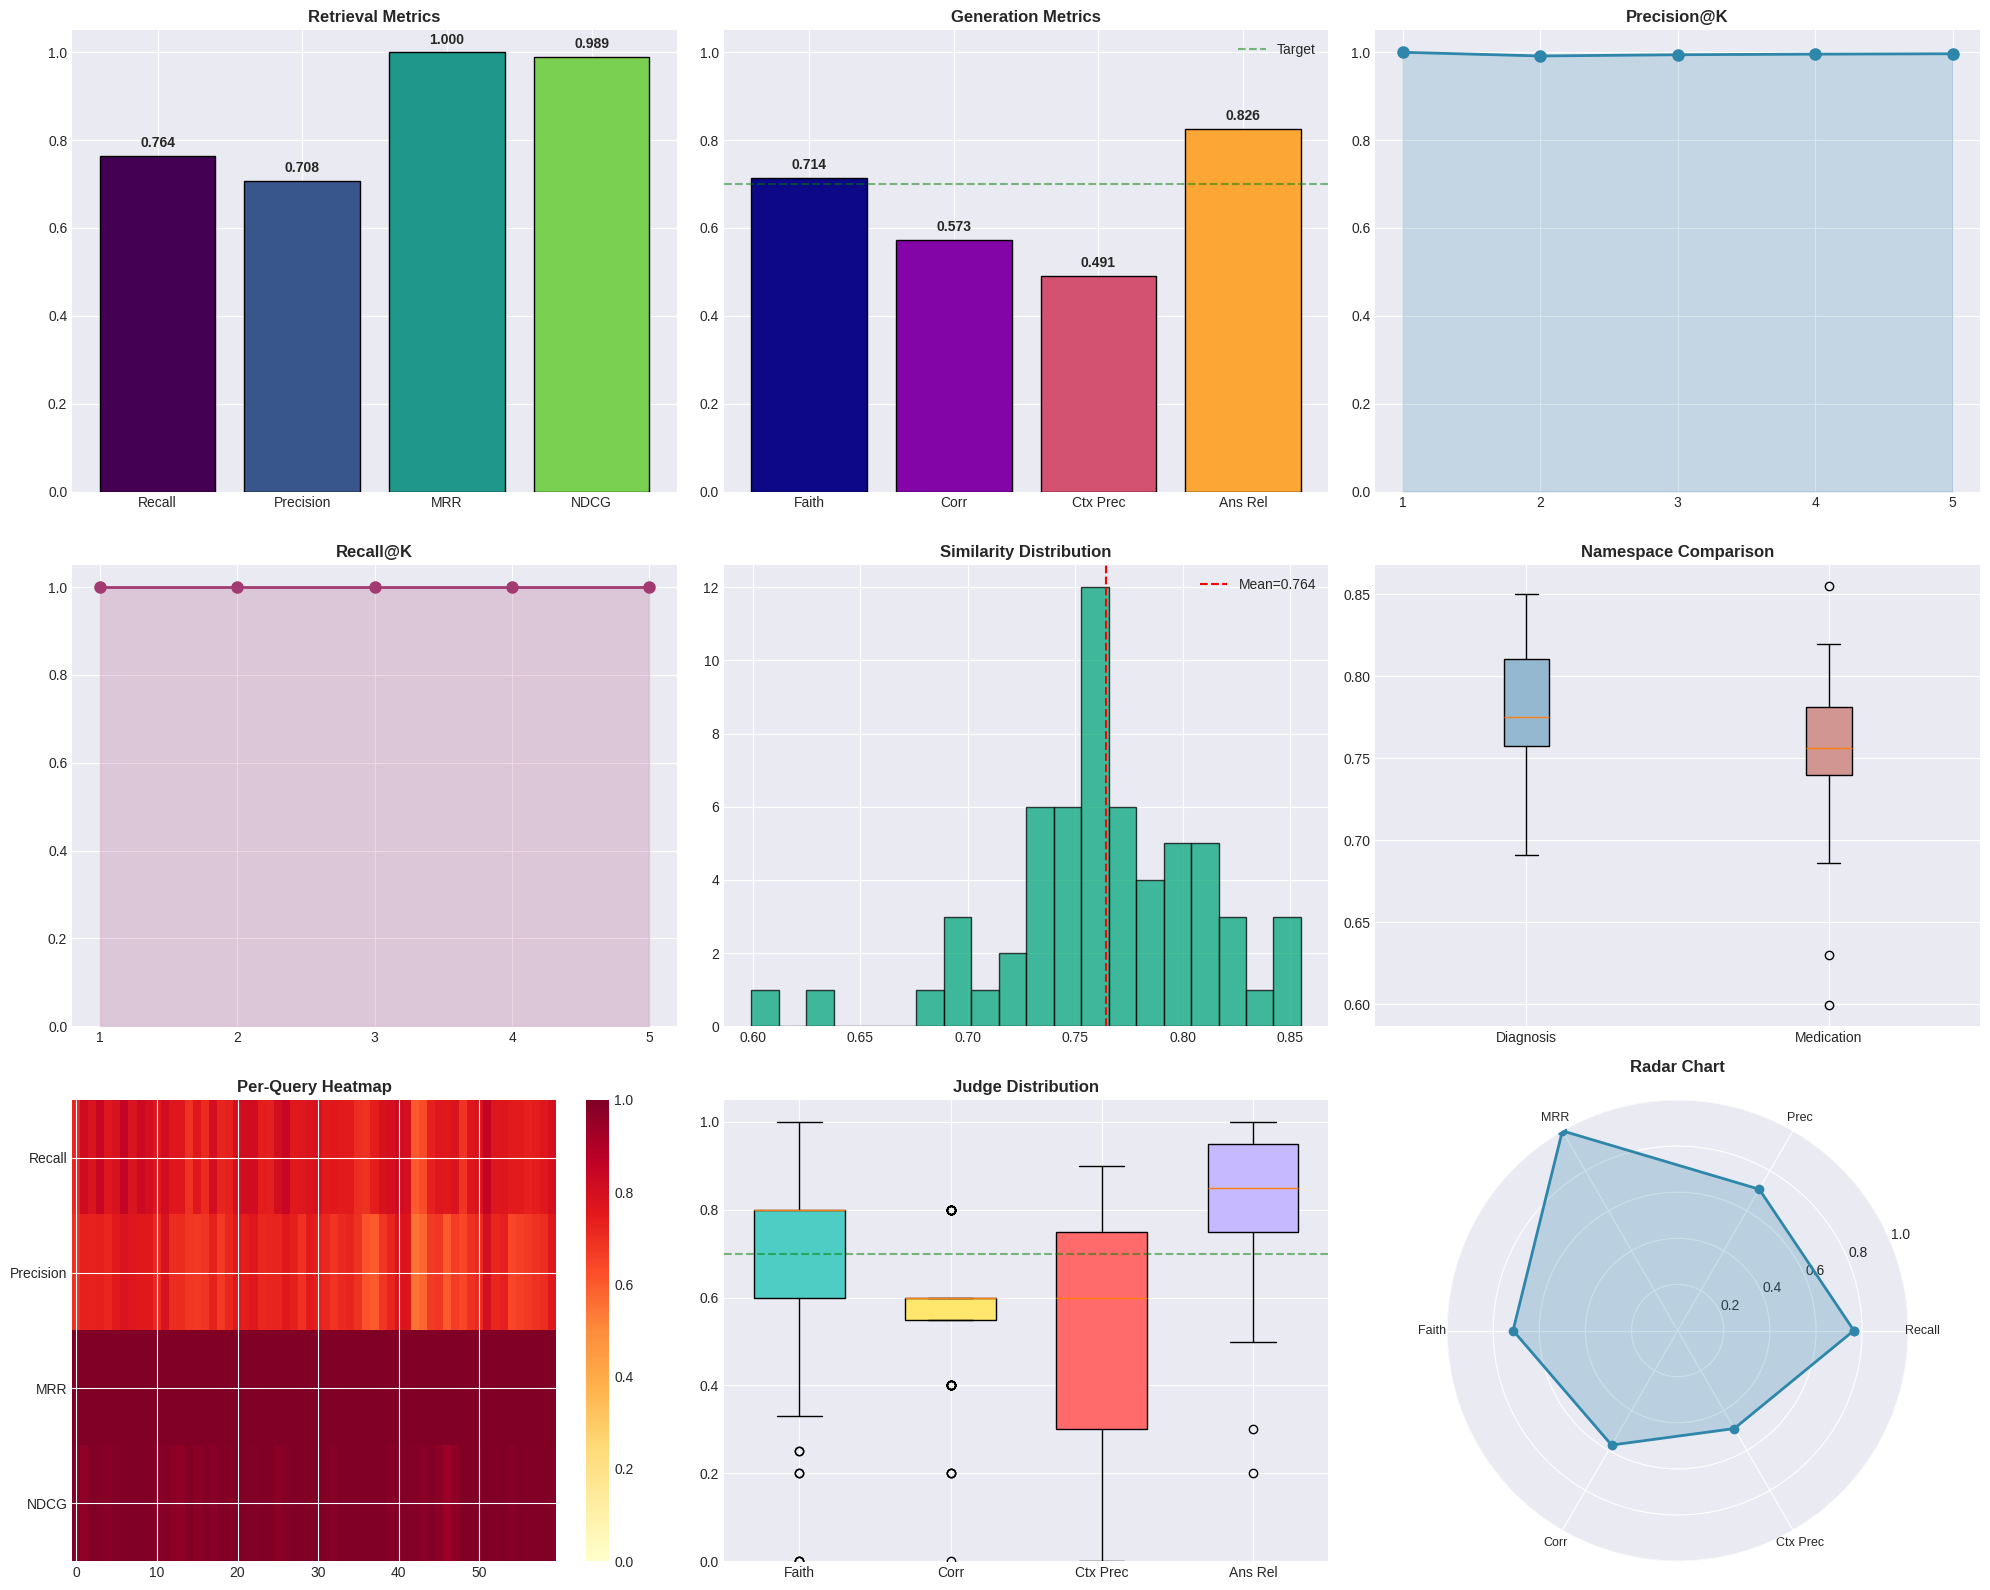

  ✓ Figure saved

  FINAL REPORT
    ┌─────────────────────────────────────┐
    │ Run:              20261025_163810   │
    │ Generator:        medgemma          │
    │ Evaluator:        qwen2.5:14b       │
    │ Queries:          60 (30D + 30M)    │
    │ Success rate:     100.0%            │
    │ Reranker:         ON                │
    │ Total runtime:    25.1 min          │
    └─────────────────────────────────────┘

  ── RETRIEVAL ──
    context_recall         [███████████████░░░░░] 0.764
    context_precision      [██████████████░░░░░░] 0.708
    mrr                    [████████████████████] 1.000
    ndcg                   [████████████████████] 0.989

  ── GENERATION (LLM judge) ──
    faithfulness           [██████████████░░░░░░] 0.714
    correctness            [███████████░░░░░░░░░] 0.573
    context_precision      [██████████░░░░░░░░░░] 0.491
    answer_relevance       [█████████████████░░░] 0.826
    context_recall         [████████░░░░░░░░░░░░] 0.417

  ── DIAGNOSIS 

In [2]:
"""
PART B — FULL EVALUATION PIPELINE (Dermatology / Dr. Zavian RAG agent)
Generator : MedGemma (7B)      | Judge : Qwen 2.5-14B  (both local, Ollama)
Retrieval : MedEmbed -> Pinecone -> BGE reranker
Run AFTER Part A and a kernel restart. See the section map in the markdown cell above.
"""
import os, sys, json, re, time, subprocess
from collections import Counter
from datetime import datetime
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from dotenv import load_dotenv
import ollama
from langchain_core.prompts import PromptTemplate
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_pinecone import PineconeVectorStore
from sentence_transformers import SentenceTransformer, CrossEncoder

try:
    from kaggle_secrets import UserSecretsClient
except ImportError:
    UserSecretsClient = None

# ============================================================
# 0. HELPERS — progress display only
#    Pretty-print utilities (headers, key/value rows, ASCII score bars).
#    They do NOT affect any metric.
# ============================================================
def h1(title):
    print("\n" + "=" * 78)
    print(f"  {title}")
    print("=" * 78)

def h2(title):
    print("\n" + "─" * 78)
    print(f"  {title}")
    print("─" * 78)

def kv(key, value, indent=4, width=28):
    print(f"{' ' * indent}{key:<{width}} {value}")

def truncate(text, n=120):
    text = text.replace("\n", " ").strip()
    return text if len(text) <= n else text[:n-3] + "..."

def box(lines, indent=4):
    """Draw a simple ASCII box around lines."""
    if not lines:
        return
    w = max(len(l) for l in lines) + 4
    print(" " * indent + "┌" + "─" * w + "┐")
    for l in lines:
        print(" " * indent + "│ " + l.ljust(w - 2) + " │")
    print(" " * indent + "└" + "─" * w + "┘")

def score_bar(score, width=20):
    """ASCII bar for 0-1 scores."""
    filled = int(round(score * width))
    bar = "█" * filled + "░" * (width - filled)
    return f"[{bar}] {score:.3f}"

# ============================================================
# 1. START OLLAMA SERVER + PULL MODELS
#    GENERATOR_MODEL produces the answers; EVALUATOR_MODEL (a different model family)
#    acts as the LLM judge -> avoids self-evaluation bias.
# ============================================================
h1("STEP 1/7 · OLLAMA SERVER + MODELS")

GENERATOR_MODEL = "medgemma"
EVALUATOR_MODEL = "qwen2.5:14b"

try:
    subprocess.run(["ollama", "list"], check=True, capture_output=True, timeout=5)
    kv("Status", "Server already running")
except Exception:
    print("  Status                         Starting server...")
    with open("ollama_server.log", "w") as f:
        subprocess.Popen(["ollama", "serve"], stdout=f, stderr=f)
    time.sleep(10)
    try:
        subprocess.run(["ollama", "list"], check=True, capture_output=True, timeout=10)
        kv("Status", "Server up")
    except Exception as e:
        raise RuntimeError(f"Ollama server failed to start: {e}") from e

for m in [GENERATOR_MODEL, EVALUATOR_MODEL]:
    print(f"  Ensuring {m:<18} ...", end="", flush=True)
    subprocess.run(["ollama", "pull", m], check=True, capture_output=True)
    print(" OK")

# ============================================================
# 2. CONFIGURATION  (all tunable parameters live here)
#    SIMILARITY_THRESHOLD : a chunk counts as 'relevant' if cos-sim(ground truth, chunk) >= 0.50
#    K_RETRIEVE_FOR_RERANK : candidates fetched from Pinecone before reranking (10)
#    K_RETRIEVAL          : chunks kept after reranking and given to the generator (5)
#    MAX_CHUNK_LENGTH     : texts are truncated to this many chars before embedding (metric side)
#    GENERATOR/EVALUATOR_MAX_TOKENS : output limits for answer (600) and judge JSON (1000)
#    NUM_CTX              : Ollama context window (16,384 tokens)
#    CONTEXT_MAX_CHARS / CONTEXT_CHARS_PER_DOC : context budget given to the generator (7,000 total, 1,200 per chunk)
# ============================================================
h1("STEP 2/7 · CONFIGURATION")

SIMILARITY_THRESHOLD   = 0.50
MAX_CHUNK_LENGTH       = 2000
K_RETRIEVAL            = 5
K_RETRIEVE_FOR_RERANK  = 10
GENERATOR_MAX_TOKENS   = 600
EVALUATOR_MAX_TOKENS   = 1000
NUM_CTX                = 16384
STREAM_ANSWERS         = True   # set True if you want to watch token output
CONTEXT_MAX_CHARS       = 7000
CONTEXT_CHARS_PER_DOC  = 1200
PINECONE_INDEX_NAME    = "dermatologist"
N_DIAGNOSIS_QUESTIONS  = 30
N_MEDICATION_QUESTIONS = 30
DATASET_PATH = "/kaggle/input/datasets/salmankey/dermatology-evaluation-dataset2/dermatology_evaluation_dataset).csv"  # path as used in the original run

kv("Generator model", GENERATOR_MODEL)
kv("Evaluator model", EVALUATOR_MODEL)
kv("Index", PINECONE_INDEX_NAME)
kv("Context budget (chars)", f"{CONTEXT_MAX_CHARS} total / {CONTEXT_CHARS_PER_DOC} per chunk")
kv("K (retrieve → rerank → final)", f"{K_RETRIEVE_FOR_RERANK} → {K_RETRIEVAL}")
kv("Similarity threshold", SIMILARITY_THRESHOLD)
kv("Generation max tokens", GENERATOR_MAX_TOKENS)
kv("Evaluation max tokens", EVALUATOR_MAX_TOKENS)
kv("Diagnosis queries", N_DIAGNOSIS_QUESTIONS)
kv("Medication queries", N_MEDICATION_QUESTIONS)
kv("Stream answers", STREAM_ANSWERS)

# ============================================================
# 3. API CREDENTIALS
#    Only the Pinecone key is needed (vector DB). No LLM API key is used:
#    both LLMs run locally through Ollama.
# ============================================================
h1("STEP 3/7 · API CREDENTIALS")

load_dotenv()
PINECONE_KEY = os.getenv("PINECONE_API_KEY")
if not PINECONE_KEY and UserSecretsClient:
    try:
        s = UserSecretsClient()
        PINECONE_KEY = s.get_secret("PINECONE_API_KEY")
        kv("Source", "PINECONE_API_KEY")
    except Exception as e:
        print(f"  Kaggle secrets failed: {e}")

if not PINECONE_KEY:
    raise RuntimeError("PINECONE_API_KEY not found")
os.environ["PINECONE_API_KEY"] = PINECONE_KEY
os.environ["LANGCHAIN_TRACING_V2"] = "false"
kv("Status", "Loaded OK")

# ============================================================
# 4. EMBEDDING MODELS + RERANKER
#    embedding_model  : MedEmbed-base-v0.1 (768-d) - used to query Pinecone
#    similarity_model : bge-large-en-v1.5 - used ONLY to compute retrieval metrics
#    reranker         : bge-reranker-v2-m3 cross-encoder - re-orders the top-10 -> top-5
#    Embeddings are L2-normalised, so dot product == cosine similarity.
# ============================================================
h1("STEP 4/7 · EMBEDDING MODELS + RERANKER")

print("  Loading MedEmbed (embedding model)...", end="", flush=True)
embedding_model = HuggingFaceEmbeddings(
    model_name="abhinand/MedEmbed-base-v0.1",
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True},
)
print(" OK")

print("  Loading BGE similarity model...", end="", flush=True)
similarity_model = SentenceTransformer("BAAI/bge-large-en-v1.5", device="cpu")
print(" OK")

print("  Loading BGE reranker...", end="", flush=True)
try:
    reranker = CrossEncoder("BAAI/bge-reranker-v2-m3")
    USE_RERANKER = True
    print(" OK")
except Exception as e:
    print(f" FAILED ({e})")
    reranker = None
    USE_RERANKER = False

kv("Reranker enabled", USE_RERANKER)

# ============================================================
# 5. PROMPTS
#    1 generation prompt (context-only, verbatim numbers, <=6 bullets)
#    5 judge prompts (RAGAS-style) -> each returns JSON {score, reasoning}
# ============================================================
h1("STEP 5/7 · PROMPTS")

ANSWER_GENERATION_PROMPT = PromptTemplate(
    input_variables=["question", "context"],
    template="""You are a dermatology specialist writing a comprehensive clinical answer.

RULES:
1. Use ONLY information from the CONTEXT below.
2. QUOTE SPECIFIC NUMBERS VERBATIM when present.
3. Include drug name, dose, route, frequency, duration, rationale,
   contraindications, alternatives — when present.
4. DO NOT REPEAT YOURSELF. Max 6 bullet points. Finish every sentence.
5. Aim for 150-300 words.

QUESTION: {question}
CONTEXT:
{context}
ANSWER:"""
)

FAITHFULNESS_PROMPT = PromptTemplate(
    input_variables=["question", "answer", "context"],
    template="""Evaluate if the ANSWER is FAITHFULLY grounded in the CONTEXT.
Score = supported claims / total claims. Be strict.
Output ONLY JSON: {{"faithfulness_score": 0.0-1.0, "reasoning": "brief"}}

QUESTION: {question}
CONTEXT: {context}
ANSWER: {answer}"""
)

ANSWER_CORRECTNESS_PROMPT = PromptTemplate(
    input_variables=["question", "answer", "ground_truth"],
    template="""Compare the ANSWER to the GROUND TRUTH.
- 1.0 = all key facts | 0.8 = most | 0.6 = core | 0.4 = misses core | 0.2 = barely | 0.0 = wrong
Output ONLY JSON: {{"correctness_score": 0.0-1.0, "reasoning": "brief"}}

QUESTION: {question}
GROUND TRUTH: {ground_truth}
ANSWER: {answer}"""
)

CONTEXT_PRECISION_PROMPT = PromptTemplate(
    input_variables=["question", "context"],
    template="""Score proportion of CONTEXT relevant to QUESTION.
Output ONLY JSON: {{"context_precision_score": 0.0-1.0, "reasoning": "brief"}}

QUESTION: {question}
CONTEXT: {context}"""
)

ANSWER_RELEVANCE_PROMPT = PromptTemplate(
    input_variables=["question", "answer"],
    template="""Score how RELEVANT the ANSWER is to the QUESTION.
Output ONLY JSON: {{"answer_relevance_score": 0.0-1.0, "reasoning": "brief"}}

QUESTION: {question}
ANSWER: {answer}"""
)

CONTEXT_RECALL_PROMPT = PromptTemplate(
    input_variables=["ground_truth", "context"],
    template="""Score proportion of GROUND TRUTH covered in CONTEXT.
Output ONLY JSON: {{"context_recall_score": 0.0-1.0, "reasoning": "brief"}}

GROUND TRUTH: {ground_truth}
CONTEXT: {context}"""
)

kv("Generation prompt", "comprehensive clinical, verbatim quoting, no repetition")
kv("Judge prompts", "5 × RAGAS-style JSON")

# ============================================================
# 6. CLASSES
#    OllamaChat   : thin wrapper over ollama.chat (JSON mode for judging, streaming for answers)
#    LLMEvaluator : answer generation with GUARDRAILS + the 5 LLM-judge metrics
# ============================================================
class OllamaChat:
    """Minimal Ollama client. invoke() = JSON-mode call (judge); stream_invoke() = streamed text (generator)."""
    def __init__(self, model, temperature=0, max_tokens=1000, num_ctx=16384):
        self.model = model
        self.options = {
            "temperature": temperature,
            "num_predict": max_tokens,
            "num_ctx": num_ctx,
            "stop": ["\n\nUser:", "\n\nQuestion:", "\n\nHuman:", "</s>", "<|eot_id|>"],
        }

    def invoke(self, prompt):
        resp = ollama.chat(
            model=self.model,
            messages=[{"role": "user", "content": prompt}],
            options=self.options, format="json",
        )
        return resp["message"]["content"]

    def stream_invoke(self, prompt, echo=True, temperature_override=None):
        opts = dict(self.options)
        if temperature_override is not None:
            opts["temperature"] = temperature_override
        stream = ollama.chat(
            model=self.model,
            messages=[{"role": "user", "content": prompt}],
            options=opts, stream=True,
        )
        text = ""
        for chunk in stream:
            piece = chunk["message"]["content"]
            text += piece
            if echo:
                print(piece, end="", flush=True)
        if echo:
            print()
        return text


class LLMEvaluator:
    """Generates answers (with guardrails) and scores them with the judge model."""
    def __init__(self, gen_model, eval_model):
        self.generator_llm = OllamaChat(gen_model, max_tokens=GENERATOR_MAX_TOKENS, num_ctx=NUM_CTX)
        self.evaluator_llm = OllamaChat(eval_model, max_tokens=EVALUATOR_MAX_TOKENS, num_ctx=NUM_CTX)
        kv("Generator", gen_model)
        kv("Evaluator", eval_model)

    @staticmethod
    def _parse_json(text):
        # Extract the first {...} block from the judge reply; returns {} if unparsable (score then defaults to 0).
        m = re.search(r"\{.*\}", text, re.DOTALL)
        if not m:
            return {}
        try:
            return json.loads(m.group())
        except json.JSONDecodeError:
            return {}

    @staticmethod
    def _is_loop(text):
        # GUARDRAIL 1 - repetition loop: >=3 identical lines, last-200-chars repeated >=3x, or type/token ratio < 0.15
        if len(text) < 300:
            return False
        lines = [l.strip() for l in text.split("\n") if l.strip()]
        if len(lines) >= 3 and Counter(lines).most_common(1)[0][1] >= 3:
            return True
        if len(text) >= 400 and text.count(text[-200:]) >= 3:
            return True
        words = text.lower().split()
        if len(words) > 100 and len(set(words)) / len(words) < 0.15:
            return True
        return False

    @staticmethod
    def _truncate(text):
        # Fallback clean-up: cut at the first repeated line and make sure the text ends with punctuation.
        lines = text.split("\n")
        seen, out = set(), []
        for line in lines:
            s = line.strip()
            if not s:
                out.append(line); continue
            if s in seen:
                break
            seen.add(s); out.append(line)
        r = "\n".join(out).rstrip()
        return r if not r or r.endswith((".", "!", "?")) else r + "."

    def generate_with_retry(self, question, context, retries=2):
        # Generate once, then check 4 failure modes and regenerate (max `retries`) if any is detected:
        #   loop | truncated (no terminal punctuation) | vague dose wording | missing numeric dose on drug/treatment questions
        prompt = ANSWER_GENERATION_PROMPT.format(question=question, context=context[:12000])
        print(f"    → Generating answer with {self.generator_llm.model}...")
        t0 = time.time()
        answer = self.generator_llm.stream_invoke(prompt, echo=STREAM_ANSWERS).strip()
        dt = time.time() - t0
        print(f"      ✓ {len(answer)} chars in {dt:.1f}s")

        for attempt in range(retries):
            is_loop = self._is_loop(answer)
            is_trunc = answer and not answer.rstrip().endswith((".", "!", "?", ")", "]"))
            is_vague = bool(re.search(r"(appropriate dose|individualized|dose per (weight|age))", answer, re.I))
            has_dose = bool(re.search(r"\d+\s*(%|mg|mcg|g|ml|units?|mg/kg|iu|meq)", answer, re.I))  # "%" added: topical strengths (e.g. 0.05%)
            needs_dose = bool(re.search(r"(treatment|regimen|drug|antibiotic|therapy|dose|duration)", question, re.I))
            is_missing = needs_dose and not has_dose and not is_loop

            if not (is_loop or is_trunc or is_vague or is_missing):
                break

            reasons = [r for r, f in [("loop", is_loop), ("trunc", is_trunc),
                                       ("vague", is_vague), ("missing", is_missing)] if f]
            print(f"      ⚠ Retry {attempt+1}/{retries} ({', '.join(reasons)})")

            rq = question
            if is_loop:
                rq += "\n\nCRITICAL: Do not repeat. Write 3-5 bullet points only. State diagnosis and evidence plainly."
            if is_trunc:
                rq += "\n\nCRITICAL: Finish every sentence with a period."
            if is_vague or is_missing:
                rq += "\n\nCRITICAL: Quote specific doses/concentrations verbatim from context."

            rp = ANSWER_GENERATION_PROMPT.format(question=rq, context=context[:12000])
            temp = 0.3 if is_loop else 0
            cand = self.generator_llm.stream_invoke(rp, echo=STREAM_ANSWERS, temperature_override=temp).strip()
            print(f"      → {len(cand)} chars")

            if not self._is_loop(cand) and len(cand) > 50:
                answer = cand
            else:
                answer = self._truncate(answer)
                break

        if self._is_loop(answer):
            answer = self._truncate(answer)
        return answer

    def judge(self, template, **kwargs):
        # Fill a judge prompt, call the evaluator model in JSON mode, parse the JSON.
        return self._parse_json(self.evaluator_llm.invoke(template.format(**kwargs)))

    def evaluate_all(self, q, ans, gt, ctx):
        # The 5 LLM-as-judge metrics (all scored in [0,1]); judge sees at most 3000 chars of context, 2000 of ground truth.
        h2("Running LLM-as-judge (5 metrics)")
        results = {}

        print("    [1/5] Faithfulness...", end="", flush=True)
        t0 = time.time()
        results["faithfulness"] = self.judge(FAITHFULNESS_PROMPT, question=q, answer=ans, context=ctx[:3000])
        print(f" {results['faithfulness'].get('faithfulness_score', 0):.3f}  ({time.time()-t0:.1f}s)")

        print("    [2/5] Answer correctness...", end="", flush=True)
        t0 = time.time()
        results["correctness"] = self.judge(ANSWER_CORRECTNESS_PROMPT, question=q, answer=ans, ground_truth=gt[:2000])
        print(f" {results['correctness'].get('correctness_score', 0):.3f}  ({time.time()-t0:.1f}s)")

        print("    [3/5] Context precision...", end="", flush=True)
        t0 = time.time()
        results["context_precision"] = self.judge(CONTEXT_PRECISION_PROMPT, question=q, context=ctx[:3000])
        print(f" {results['context_precision'].get('context_precision_score', 0):.3f}  ({time.time()-t0:.1f}s)")

        print("    [4/5] Answer relevance...", end="", flush=True)
        t0 = time.time()
        results["relevance"] = self.judge(ANSWER_RELEVANCE_PROMPT, question=q, answer=ans)
        print(f" {results['relevance'].get('answer_relevance_score', 0):.3f}  ({time.time()-t0:.1f}s)")

        print("    [5/5] Context recall...", end="", flush=True)
        t0 = time.time()
        results["context_recall"] = self.judge(CONTEXT_RECALL_PROMPT, ground_truth=gt[:2000], context=ctx[:3000])
        print(f" {results['context_recall'].get('context_recall_score', 0):.3f}  ({time.time()-t0:.1f}s)")

        return results

# ============================================================
# 7. RETRIEVAL + EMBEDDING-BASED METRICS
#    sem_sim(a,b)            : cosine similarity with BGE-large (cached)
#    retrieve()              : Pinecone top-10 -> cross-encoder rerank -> top-5
#    combine_context()       : builds the generator context (<=7,000 chars, <=1,200 per chunk)
#    retrieval_metrics()     : Recall(max sim), Precision(mean sim), MRR, NDCG, P@k, R@k
# ============================================================
@lru_cache(maxsize=1000)
def _encode(text):
    # Cached, L2-normalised BGE-large embedding (text truncated to MAX_CHUNK_LENGTH).
    if len(text) > MAX_CHUNK_LENGTH:
        text = text[:MAX_CHUNK_LENGTH]
    return similarity_model.encode([text], normalize_embeddings=True)

def sem_sim(a, b):
    return float(np.dot(_encode(a)[0], _encode(b)[0]))

def retrieve(query, namespace):
    store = PineconeVectorStore(
        index_name=PINECONE_INDEX_NAME, embedding=embedding_model, namespace=namespace)
    k = K_RETRIEVE_FOR_RERANK if USE_RERANKER else K_RETRIEVAL
    docs = store.as_retriever(search_kwargs={"k": k}).invoke(query)

    if not USE_RERANKER or reranker is None or len(docs) <= 1:
        return docs[:K_RETRIEVAL]

    scores = reranker.predict([[query, d.page_content] for d in docs])
    ranked = sorted(zip(docs, scores), key=lambda x: x[1], reverse=True)
    out = []
    for doc, score in ranked[:K_RETRIEVAL]:
        doc.metadata["rerank_score"] = float(score)
        out.append(doc)
    return out

def combine_context(docs, max_chars=CONTEXT_MAX_CHARS, per_doc_chars=CONTEXT_CHARS_PER_DOC):
    parts, total = [], 0
    for i, d in enumerate(docs, 1):
        chunk = d.page_content[:per_doc_chars]
        part = f"[Doc {i}]\n{chunk}\n"
        if total + len(part) > max_chars:
            break
        parts.append(part)
        total += len(part)
    return "\n".join(parts)

def retrieval_metrics(gt, docs):
    # sims[i] = cos(ground_truth, doc_i). Relevant <=> sims[i] >= SIMILARITY_THRESHOLD.
    #   recall    = max(sims)            precision = mean(sims)
    #   mrr       = 1/rank of first relevant doc
    #   ndcg      = DCG/IDCG with graded gain = sim
    #   P@k / R@k = fraction relevant in top-k / any relevant in top-k
    if not docs:
        return dict(recall=0, precision=0, mrr=0, ndcg=0, p_at_k={}, r_at_k={}, sims=[])
    sims = [sem_sim(gt, d.page_content) for d in docs]
    mrr = 0.0
    for rank, s in enumerate(sims, 1):
        if s >= SIMILARITY_THRESHOLD:
            mrr = 1.0 / rank; break
    dcg = sum(s / np.log2(i + 2) for i, s in enumerate(sims))
    idcg = sum(s / np.log2(i + 2) for i, s in enumerate(sorted(sims, reverse=True)))
    ndcg = dcg / idcg if idcg > 0 else 0.0
    p_at_k = {k: sum(1 for s in sims[:k] if s >= SIMILARITY_THRESHOLD) / k for k in [1,2,3,4,5]}
    r_at_k = {k: float(any(s >= SIMILARITY_THRESHOLD for s in sims[:k])) for k in [1,2,3,4,5]}
    return dict(recall=float(max(sims)), precision=float(np.mean(sims)),
                mrr=float(mrr), ndcg=float(ndcg), p_at_k=p_at_k, r_at_k=r_at_k, sims=sims)

# ============================================================
# 8. PIN MODELS IN GPU MEMORY
#    keep_alive=30m prevents Ollama from unloading/reloading models between queries.
# ============================================================
h1("STEP 6/7 · PIN MODELS IN GPU")

for m in [GENERATOR_MODEL, EVALUATOR_MODEL]:
    try:
        ollama.generate(model=m, prompt=".", keep_alive="30m")
        print(f"  ✓ {m} pinned (30 min)")
    except Exception as e:
        print(f"  ⚠ Could not pin {m}: {e}")

# ============================================================
# 9. LOAD DATASET
#    Takes the first 50 'diagnosis_knowledge' + first 50 'medication_knowledge' rows (100 queries).
#    Columns used: question, ground_truth, namespace.
# ============================================================
h1("STEP 7/7 · LOAD DATASET")

dataset = pd.read_csv(DATASET_PATH)
diag = dataset[dataset.namespace == "diagnosis_knowledge"].head(N_DIAGNOSIS_QUESTIONS)
med = dataset[dataset.namespace == "medication_knowledge"].head(N_MEDICATION_QUESTIONS)
selected = pd.concat([diag, med], ignore_index=True)

kv("Dataset path", DATASET_PATH.split("/")[-1])
kv("Total rows in file", len(dataset))
kv("Diagnosis queries", len(diag))
kv("Medication queries", len(med))
kv("Queries to evaluate", len(selected))

# ============================================================
# 10. EVALUATION LOOP  (one iteration = one query)
#    a) retrieve + rerank  b) build context  c) generate answer (with guardrails)
#    d) retrieval metrics  e) 5 LLM-judge metrics  f) store record
#    If a query raises an exception it is logged and stored with all scores = 0.
# ============================================================
h1("EVALUATION LOOP")
print(f"  Running {len(selected)} queries with {GENERATOR_MODEL} → {EVALUATOR_MODEL}")
print(f"  Progress bar shows overall completion.\n")

llm_evaluator = LLMEvaluator(GENERATOR_MODEL, EVALUATOR_MODEL)
results, judgments = [], []

run_start = time.time()
pbar = tqdm(range(len(selected)), desc="Overall", ncols=100, unit="query")

for idx in pbar:
    row = selected.iloc[idx]
    question, ground_truth, namespace = row.question, row.ground_truth, row.namespace

    print("\n" + "╔" + "═" * 76 + "╗")
    print(f"║ QUERY {idx+1}/{len(selected)}  ·  {namespace.upper():<30}║")
    print("╚" + "═" * 76 + "╝")
    pbar.set_postfix_str(f"[{idx+1}/{len(selected)}] {namespace.split('_')[0]}")

    print(f"  Q: {question}\n")

    try:
        # ---------- (a,b) Retrieval + rerank + context ----------
        print("  ── RETRIEVAL ──")
        t0 = time.time()
        docs = retrieve(question, namespace)
        dt = time.time() - t0
        if not docs:
            raise ValueError("No docs retrieved")

        print(f"  {len(docs)} docs retrieved in {dt:.1f}s")
        print(f"  Reranker: {'ON' if USE_RERANKER else 'OFF'}\n")

        # Show retrieved docs with scores
        print(f"  {'Rank':<6} {'Rerank':>8}  Preview")
        print(f"  {'-'*6} {'-'*8}  {'-'*58}")
        for i, d in enumerate(docs, 1):
            score = d.metadata.get("rerank_score", None)
            score_str = f"{score:.4f}" if score is not None else "  --  "
            preview = truncate(d.page_content, 60)
            print(f"  {i:<6} {score_str:>8}  {preview}")

        context = combine_context(docs)
        print(f"\n  Context built: {len(context)} chars\n")

        # ---------- (c) Generation with guardrails ----------
        print("  ── GENERATION ──")
        answer = llm_evaluator.generate_with_retry(question, context)
        print(f"\n  Answer preview:")
        for line in answer.split("\n")[:5]:
            print(f"    {truncate(line, 70)}")
        if answer.count("\n") > 5:
            print(f"    ... ({answer.count(chr(10)) - 5} more lines)")

        # ---------- (d) Embedding-based retrieval metrics ----------
        print("\n  ── RETRIEVAL METRICS ──")
        rm = retrieval_metrics(ground_truth, docs)
        print(f"    Recall (continuous)  {score_bar(rm['recall'])}")
        print(f"    Precision (cont.)    {score_bar(rm['precision'])}")
        print(f"    MRR                  {score_bar(rm['mrr'])}")
        print(f"    NDCG                 {score_bar(rm['ndcg'])}")
        print(f"    P@k                  " + "  ".join(
            f"@{k}={rm['p_at_k'][k]:.2f}" for k in [1,2,3,4,5]))
        print(f"    R@k                  " + "  ".join(
            f"@{k}={rm['r_at_k'][k]:.2f}" for k in [1,2,3,4,5]))

        # ---------- (e) LLM-as-judge metrics ----------
        jm = llm_evaluator.evaluate_all(question, answer, ground_truth, context)

        # ---------- (f) Store per-query records ----------
        j_record = {
            "query_id": idx + 1, "namespace": namespace, "question": question,
            "generated_answer": answer,
            "faithfulness": jm["faithfulness"].get("faithfulness_score", 0),
            "answer_correctness": jm["correctness"].get("correctness_score", 0),
            "context_precision_llm": jm["context_precision"].get("context_precision_score", 0),
            "answer_relevance": jm["relevance"].get("answer_relevance_score", 0),
            "context_recall_llm": jm["context_recall"].get("context_recall_score", 0),
        }
        judgments.append(j_record)

        results.append({
            "query_id": idx + 1, "namespace": namespace, "question": question,
            "ground_truth": ground_truth[:500], "generated_answer": answer[:500],
            "recall_continuous": rm["recall"],
            "precision_continuous": rm["precision"],
            "mrr": rm["mrr"], "ndcg_graded": rm["ndcg"],
            "best_similarity": rm["recall"],
            **{f"precision@{k}": v for k, v in rm["p_at_k"].items()},
            **{f"recall@{k}": v for k, v in rm["r_at_k"].items()},
            **{k: j_record[k] for k in [
                "faithfulness", "answer_correctness",
                "context_precision_llm", "answer_relevance", "context_recall_llm"]},
        })

        h2("Query score summary")
        print(f"    Faithfulness      {score_bar(j_record['faithfulness'])}")
        print(f"    Answer Correctness{score_bar(j_record['answer_correctness'])}")
        print(f"    Context Precision {score_bar(j_record['context_precision_llm'])}")
        print(f"    Answer Relevance  {score_bar(j_record['answer_relevance'])}")
        print(f"    Context Recall    {score_bar(j_record['context_recall_llm'])}")

    except Exception as e:
        print(f"\n  ✗ ERROR: {e}")
        import traceback; traceback.print_exc()
        results.append({
            "query_id": idx + 1, "namespace": namespace, "question": question,
            "ground_truth": ground_truth[:500], "generated_answer": f"ERROR: {e}",
            **{k: 0 for k in [
                "recall_continuous","precision_continuous","mrr","ndcg_graded",
                "best_similarity","faithfulness","answer_correctness",
                "context_precision_llm","answer_relevance","context_recall_llm",
                "precision@1","precision@2","precision@3","precision@4","precision@5",
                "recall@1","recall@2","recall@3","recall@4","recall@5"]},
        })

pbar.close()
elapsed = time.time() - run_start
print(f"\n{'='*78}")
print(f"  Loop completed in {elapsed/60:.1f} min ({elapsed/len(selected):.1f}s per query)")
print(f"{'='*78}")

# ============================================================
# 11. AGGREGATE + SAVE RESULTS
#    Overall metrics = mean over queries with best_similarity > 0 (retrieval) / all judged queries (generation).
#    success_rate = queries with >=1 retrieved chunk / total queries (system reliability, not correctness).
#    Saves: results CSV, judgments CSV, metrics JSON.
# ============================================================
h1("AGGREGATING RESULTS")

results_df = pd.DataFrame(results)
judgments_df = pd.DataFrame(judgments)

if judgments_df.empty:
    print("  ✗ WARNING: no judgments collected — all queries failed")
else:
    diag_df = results_df[results_df.namespace == "diagnosis_knowledge"]
    med_df = results_df[results_df.namespace == "medication_knowledge"]
    valid = results_df[results_df.best_similarity > 0]

    def subset(df):
        if df.empty:
            return {}
        return {
            "recall": float(df.recall_continuous.mean()),
            "precision": float(df.precision_continuous.mean()),
            "mrr": float(df.mrr.mean()),
            "faithfulness": float(df.faithfulness.mean()),
            "correctness": float(df.answer_correctness.mean()),
            "answer_relevance": float(df.answer_relevance.mean()),
        }

    run_tag = datetime.now().strftime("%Y%m%d_%H%M%S")
    summary = {
        "run_tag": run_tag,
        "timestamp": datetime.now().isoformat(),
        "generator_model": GENERATOR_MODEL,
        "evaluator_model": EVALUATOR_MODEL,
        "n_queries": len(results_df),
        "n_diagnosis": len(diag_df),
        "n_medication": len(med_df),
        "success_rate": float(len(valid) / len(results_df)) if len(results_df) else 0,
        "overall_retrieval": {
            "context_recall": float(valid.recall_continuous.mean()),
            "context_precision": float(valid.precision_continuous.mean()),
            "mrr": float(valid.mrr.mean()),
            "ndcg": float(valid.ndcg_graded.mean()),
            **{f"precision@{k}": float(valid[f"precision@{k}"].mean()) for k in [1,2,3,4,5]},
            **{f"recall@{k}": float(valid[f"recall@{k}"].mean()) for k in [1,2,3,4,5]},
        },
        "overall_generation": {
            "faithfulness": float(judgments_df.faithfulness.mean()),
            "correctness": float(judgments_df.answer_correctness.mean()),
            "context_precision": float(judgments_df.context_precision_llm.mean()),
            "answer_relevance": float(judgments_df.answer_relevance.mean()),
            "context_recall": float(judgments_df.context_recall_llm.mean()),
        },
        "diagnosis": subset(diag_df),
        "medication": subset(med_df),
    }

    ev_suffix = EVALUATOR_MODEL.replace(":", "-").replace("/", "-")
    rk_suffix = "_with_reranker" if USE_RERANKER else "_no_reranker"
    results_df.to_csv(f"derm_results_{run_tag}_{ev_suffix}{rk_suffix}.csv", index=False)
    judgments_df.to_csv(f"derm_judgments_{run_tag}_{ev_suffix}{rk_suffix}.csv", index=False)
    with open(f"derm_metrics_{run_tag}_{ev_suffix}{rk_suffix}.json", "w") as f:
        json.dump(summary, f, indent=2)

    # ============================================================
    # 12. FIGURE (9 panels)
    #    Retrieval bars | Generation bars | P@K | R@K | similarity histogram |
    #    namespace box-plot | per-query heatmap | judge-score box-plot | radar chart
    # ============================================================
    h1("GENERATING FIGURE (9 panels)")

    plt.style.use("seaborn-v0_8-darkgrid")
    fig = plt.figure(figsize=(20, 16))

    ax = fig.add_subplot(3, 3, 1)
    s = [summary["overall_retrieval"]["context_recall"],
         summary["overall_retrieval"]["context_precision"],
         summary["overall_retrieval"]["mrr"],
         summary["overall_retrieval"]["ndcg"]]
    b = ax.bar(["Recall", "Precision", "MRR", "NDCG"], s,
               color=plt.cm.viridis(np.linspace(0, .8, 4)), edgecolor="black")
    ax.set_ylim(0, 1.05); ax.set_title("Retrieval Metrics", fontweight="bold")
    for bi, v in zip(b, s): ax.text(bi.get_x()+bi.get_width()/2, bi.get_height()+.02,
                                    f"{v:.3f}", ha="center", fontweight="bold")

    ax = fig.add_subplot(3, 3, 2)
    s = [summary["overall_generation"]["faithfulness"],
         summary["overall_generation"]["correctness"],
         summary["overall_generation"]["context_precision"],
         summary["overall_generation"]["answer_relevance"]]
    b = ax.bar(["Faith", "Corr", "Ctx Prec", "Ans Rel"], s,
               color=plt.cm.plasma(np.linspace(0, .8, 4)), edgecolor="black")
    ax.set_ylim(0, 1.05); ax.axhline(.7, color="green", ls="--", alpha=.5, label="Target")
    ax.set_title("Generation Metrics", fontweight="bold"); ax.legend()
    for bi, v in zip(b, s): ax.text(bi.get_x()+bi.get_width()/2, bi.get_height()+.02,
                                    f"{v:.3f}", ha="center", fontweight="bold")

    for i, (title, key, color) in enumerate([
        ("Precision@K", "precision", "#2E86AB"),
        ("Recall@K", "recall", "#A23B72")], start=3):
        ax = fig.add_subplot(3, 3, i)
        ks = [1,2,3,4,5]
        vs = [summary["overall_retrieval"][f"{key}@{k}"] for k in ks]
        ax.plot(ks, vs, "o-", lw=2, ms=8, color=color)
        ax.fill_between(ks, vs, alpha=.2, color=color)
        ax.set_xticks(ks); ax.set_ylim(0,1.05); ax.set_title(title, fontweight="bold")

    ax = fig.add_subplot(3, 3, 5)
    sims = results_df.best_similarity.values
    ax.hist(sims, bins=20, color="#06A77D", edgecolor="black", alpha=.75)
    ax.axvline(sims.mean(), color="red", ls="--", label=f"Mean={sims.mean():.3f}")
    ax.set_title("Similarity Distribution", fontweight="bold"); ax.legend()

    ax = fig.add_subplot(3, 3, 6)
    d_s = results_df[results_df.namespace=="diagnosis_knowledge"].best_similarity
    m_s = results_df[results_df.namespace=="medication_knowledge"].best_similarity
    bp = ax.boxplot([d_s, m_s], labels=["Diagnosis","Medication"], patch_artist=True)
    bp["boxes"][0].set_facecolor("#95B8D1"); bp["boxes"][1].set_facecolor("#D19592")
    ax.set_title("Namespace Comparison", fontweight="bold")

    ax = fig.add_subplot(3, 3, 7)
    mat = results_df[["recall_continuous","precision_continuous","mrr","ndcg_graded"]].values.T
    im = ax.imshow(mat, aspect="auto", cmap="YlOrRd", vmin=0, vmax=1)
    ax.set_yticks(range(4)); ax.set_yticklabels(["Recall","Precision","MRR","NDCG"])
    ax.set_title("Per-Query Heatmap", fontweight="bold"); plt.colorbar(im, ax=ax)

    ax = fig.add_subplot(3, 3, 8)
    bp = ax.boxplot([judgments_df.faithfulness, judgments_df.answer_correctness,
                     judgments_df.context_precision_llm, judgments_df.answer_relevance],
                    positions=[1,2,3,4], widths=.6, patch_artist=True)
    for p, c in zip(bp["boxes"], ["#4ECDC4","#FFE66D","#FF6B6B","#C7B9FF"]): p.set_facecolor(c)
    ax.set_xticks([1,2,3,4]); ax.set_xticklabels(["Faith","Corr","Ctx Prec","Ans Rel"])
    ax.set_ylim(0,1.05); ax.axhline(.7, color="green", ls="--", alpha=.5)
    ax.set_title("Judge Distribution", fontweight="bold")

    ax = fig.add_subplot(3, 3, 9, projection="polar")
    cats = ["Recall","Prec","MRR","Faith","Corr","Ctx Prec"]
    vals = [summary["overall_retrieval"]["context_recall"],
            summary["overall_retrieval"]["context_precision"],
            summary["overall_retrieval"]["mrr"],
            summary["overall_generation"]["faithfulness"],
            summary["overall_generation"]["correctness"],
            summary["overall_generation"]["context_precision"]]
    ang = np.linspace(0, 2*np.pi, len(cats), endpoint=False).tolist()
    vals += vals[:1]; ang += ang[:1]
    ax.plot(ang, vals, "o-", lw=2, color="#2E86AB")
    ax.fill(ang, vals, alpha=.25, color="#2E86AB")
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(cats, fontsize=9); ax.set_ylim(0,1)
    ax.set_title("Radar Chart", fontweight="bold", pad=20)

    plt.tight_layout()
    plt.savefig(f"derm_evaluation_plots_{run_tag}.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print("  ✓ Figure saved")

    # ============================================================
    # 13. FINAL REPORT  (numbers reported in the paper - Tables 1 & 2)
    #    Printed summary box + retrieval, generation, diagnosis and medication scores.
    # ============================================================
    h1("FINAL REPORT")

    box([
        f"Run:              {run_tag}",
        f"Generator:        {GENERATOR_MODEL}",
        f"Evaluator:        {EVALUATOR_MODEL}",
        f"Queries:          {summary['n_queries']} ({summary['n_diagnosis']}D + {summary['n_medication']}M)",
        f"Success rate:     {summary['success_rate']*100:.1f}%",
        f"Reranker:         {'ON' if USE_RERANKER else 'OFF'}",
        f"Total runtime:    {elapsed/60:.1f} min",
    ])

    print(f"\n  ── RETRIEVAL ──")
    for k in ["context_recall", "context_precision", "mrr", "ndcg"]:
        print(f"    {k:<22} {score_bar(summary['overall_retrieval'][k])}")

    print(f"\n  ── GENERATION (LLM judge) ──")
    for k in ["faithfulness", "correctness", "context_precision", "answer_relevance", "context_recall"]:
        print(f"    {k:<22} {score_bar(summary['overall_generation'][k])}")

    print(f"\n  ── DIAGNOSIS ({summary['n_diagnosis']} queries) ──")
    if summary['diagnosis']:
        for k, v in summary['diagnosis'].items():
            print(f"    {k:<22} {score_bar(v)}")

    print(f"\n  ── MEDICATION ({summary['n_medication']} queries) ──")
    if summary['medication']:
        for k, v in summary['medication'].items():
            print(f"    {k:<22} {score_bar(v)}")

    print(f"\n  ── OUTPUT FILES ──")
    kv("Results CSV", f"derm_results_{run_tag}_*.csv")
    kv("Judgments CSV", f"derm_judgments_{run_tag}_*.csv")
    kv("Metrics JSON", f"derm_metrics_{run_tag}_*.json")
    kv("Figure PNG", f"derm_evaluation_plots_{run_tag}.png")

    print(f"\n{'='*78}")
    print(f"  ✅ EVALUATION COMPLETE · {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"{'='*78}")